# Missing dates
How many individuals have no birth date, no death date, no floruit, or no activity window.

- **Birth / death date**: Wikidata dates precise to the year or decade.
- **Floruit**: any of the four methods of notebook 04 (Wikidata floruit P1317, "fl." with one or two dates, median of the cleaned work dates).
- **Activity window**: any of the two methods of notebook 05 ("fl." with two dates, first to last cleaned work date), at least 2 years long.

Wikidata values only, before enrichment.

In [1]:
import duckdb
import polars as pl

from style import *

DB_PATH = '../data/cultura/humans_clean_non_enriched_v3.duckdb'

PRECISE = ['day', 'month', 'year', 'decade']
MID_DECADE = 5
MIN_RANGE = 2
FLORUIT_METHODS = ['Floruit (P1317)', '"fl." with one date', '"fl." with two dates', 'Median of work dates']
WINDOW_METHODS = ['"fl." with two dates', 'First to last work date']

pl.Config.set_tbl_rows(40)

connection = duckdb.connect(DB_PATH, read_only=True)
database_size = connection.execute('SELECT count(*) FROM individual').fetchone()[0]
print(f'{database_size:,} individuals in the database')

13,002,897 individuals in the database


## Birth and death dates

In [2]:
lifetime = connection.execute('''
    SELECT entity.qid AS qid,
           len(birth_date) > 0 AS has_birth_any,
           len(death_date) > 0 AS has_death_any,
           len([date FOR date IN birth_date IF date.precision IN ('day', 'month', 'year', 'decade')]) > 0 AS has_birth,
           len([date FOR date IN death_date IF date.precision IN ('day', 'month', 'year', 'decade')]) > 0 AS has_death
    FROM individual
''').pl()
assert lifetime.height == database_size
lifetime.select(pl.exclude('qid').sum())

has_birth_any,has_death_any,has_birth,has_death
u32,u32,u32,u32
7487896,3531434,7349789,3501000


## Floruit and activity window
The code of notebooks 04 and 05, unchanged.
### 1. Wikidata floruit (P1317)

In [3]:
floruit_property = connection.execute('''
    SELECT entity.qid AS qid,
           list_min([CASE WHEN date.precision = 'decade' THEN date.year + 5 ELSE date.year END
                     FOR date IN floruit_date IF date.precision IN ('day', 'month', 'year', 'decade')]) AS year
    FROM individual
    WHERE len(floruit_date) > 0
''').pl().drop_nulls('year')
print(f'{floruit_property.height:,} individuals with a precise floruit')

55,835 individuals with a precise floruit


### 2. "fl." in the description, with one or two dates

In [4]:
fl_pattern = r'\bfl\.\s*(?:c\.|ca\.|circa|about|in the|around)?\s*(\d{1,4})(s?)\b(?:[^,;)]*?\b(B\.?\s?C\.?(?:\s?E\.?)?))?'
range_pattern = r'\bfl\.[^,;)]*?\d\s*(?:s|st|nd|rd|th|\.)?\s*(?:-|–|—|/|\bto\b|\band\b)\s*(?:c\.\s*)?\d'
century_pattern = r'\bfl\.[^,;)]*?\b(\d{1,2})(?:st|nd|rd|th|\.)?\s*(?:-\s*\d{1,2}(?:st|nd|rd|th|\.)?\s*)?(century|centuries|millennium)(?:[^,;)]*?\b(B\.?\s?C\.?(?:\s?E\.?)?))?'

fl_text = (
    connection.execute('''
        SELECT entity.qid AS qid, entity.description AS description
        FROM individual
        WHERE regexp_matches(entity.description, '\\bfl\\.')
    ''').pl()
    .with_columns(
        pl.col('description').str.extract_groups(fl_pattern).alias('match'),
        pl.col('description').str.extract_groups(century_pattern).alias('century_match'),
        pl.col('description').str.contains(r'\bfl\.\s*\d{1,2}\.').alias('is_ordinal_century'),
    )
    .with_columns(
        pl.col('match').struct.field('1').cast(pl.Int64).alias('year'),
        pl.col('match').struct.field('2').eq('s').alias('is_decade'),
        pl.col('match').struct.field('3').is_not_null().alias('is_bc'),
        pl.col('century_match').struct.field('1').cast(pl.Int64).alias('ordinal'),
        pl.col('century_match').struct.field('2').eq('millennium').alias('is_millennium'),
        pl.col('century_match').struct.field('3').is_not_null().alias('is_century_bc'),
    )
    .with_columns(
        pl.when(pl.col('is_ordinal_century')).then(None)
        .when(pl.col('is_decade')).then(pl.col('year') + MID_DECADE)
        .otherwise(pl.col('year')).alias('year'))
    .with_columns(pl.when(pl.col('is_bc')).then(-pl.col('year')).otherwise(pl.col('year')).alias('fl_precise_year'))
    .with_columns(
        pl.when(pl.col('is_millennium')).then((pl.col('ordinal') - 1) * 1000)
        .otherwise((pl.col('ordinal') - 1) * 100).alias('coarse_year'))
    .with_columns(
        pl.when(pl.col('is_century_bc')).then(-pl.col('coarse_year') - 100 * (~pl.col('is_millennium')).cast(pl.Int64) - 1000 * pl.col('is_millennium').cast(pl.Int64))
        .otherwise(pl.col('coarse_year')).alias('fl_coarse_year'))
    .select(
        'qid', 'description',
        pl.col('fl_precise_year').is_not_null().alias('fl_precise'),
        (pl.col('fl_precise_year').is_not_null() | pl.col('fl_coarse_year').is_not_null()).alias('fl_any'),
        pl.coalesce('fl_precise_year', 'fl_coarse_year').alias('fl_year'),
        pl.col('description').str.contains(range_pattern).alias('fl_range'),
    )
)
range_years_pattern = r'\bfl\.\s*(?:c\.|ca\.|circa|about|in the|around)?\s*(\d{1,4})s?\s*(?:-|–|—|/|\bto\b|\band\b)\s*(?:c\.\s*)?(\d{1,4})'


def second_year(match):
    first, second = match['1'], match['2']
    if first is None or second is None:
        return None
    if len(second) < len(first):
        second = first[:len(first) - len(second)] + second
    return int(second)


fl_text = fl_text.with_columns(
    pl.col('description').str.extract_groups(range_years_pattern)
    .map_elements(second_year, return_dtype=pl.Int64).alias('second_year'),
    pl.col('description').str.extract_groups(range_years_pattern).struct.field('2').cast(pl.Int64).alias('written_second_year'),
).with_columns(
    pl.when(pl.col('fl_year') < 0).then(-pl.col('written_second_year')).otherwise(pl.col('second_year')).alias('second_year')
).drop('written_second_year')
assert fl_text['qid'].is_unique().all()

fl_one = fl_text.filter(pl.col('fl_precise') & (~pl.col('fl_range') | pl.col('second_year').is_null())).select(
    'qid', pl.col('fl_year').alias('year'))
fl_two = fl_text.filter(pl.col('fl_precise') & pl.col('fl_range') & pl.col('second_year').is_not_null()).select(
    'qid', ((pl.col('fl_year') + pl.col('second_year')) // 2).alias('year'))
print(f'{fl_one.height:,} individuals with "fl." and one date, {fl_two.height:,} with two dates')

fl_range = fl_text.filter(pl.col('fl_precise') & pl.col('fl_range') & pl.col('second_year').is_not_null()).select(
    'qid',
    pl.min_horizontal('fl_year', 'second_year').alias('start_year'),
    pl.max_horizontal('fl_year', 'second_year').alias('end_year'),
).filter(pl.col('end_year') - pl.col('start_year') >= MIN_RANGE)
print(f'{fl_range.height:,} individuals with a "fl." range of at least {MIN_RANGE} years')

4,184 individuals with "fl." and one date, 3,073 with two dates
2,939 individuals with a "fl." range of at least 2 years


### 3. Cleaned work dates: median and first-to-last range

In [5]:
LIFETIME_LIMIT = 100

connection.execute(f'''
    CREATE OR REPLACE TEMP TABLE clean_work AS
    WITH lifetime AS (
        SELECT entity.qid AS qid,
               list_min([date.year FOR date IN birth_date IF date.precision IN ('day', 'month', 'year', 'decade')]) AS birth_year,
               list_min([date.year FOR date IN death_date IF date.precision IN ('day', 'month', 'year', 'decade')]) AS death_year
        FROM individual
    ),
    dated AS (
        SELECT DISTINCT individual_work.qid, individual_work.work_qid,
               CASE WHEN work.inception.precision IN ('day', 'month', 'year', 'decade') THEN work.inception.year END AS inception_year,
               CASE WHEN work.publication_date.precision IN ('day', 'month', 'year', 'decade') THEN work.publication_date.year END AS publication_year,
               work.inception.precision AS inception_precision,
               work.publication_date.precision AS publication_precision
        FROM individual_work
        JOIN work ON work.entity.qid = individual_work.work_qid
    ),
    dated_with_source AS (
        SELECT qid, work_qid,
               coalesce(inception_year, publication_year) AS year,
               CASE WHEN inception_year IS NOT NULL THEN 'inception' ELSE 'publication' END AS source,
               CASE WHEN inception_year IS NOT NULL THEN inception_precision ELSE publication_precision END AS precision
        FROM dated
        WHERE coalesce(inception_year, publication_year) IS NOT NULL
    ),
    first_inception AS (
        SELECT qid, min(year) AS first_inception_year
        FROM dated_with_source
        WHERE source = 'inception'
        GROUP BY qid
    ),
    kept AS (
        SELECT dated_with_source.*, lifetime.birth_year, lifetime.death_year
        FROM dated_with_source
        JOIN lifetime ON lifetime.qid = dated_with_source.qid
        LEFT JOIN first_inception ON first_inception.qid = dated_with_source.qid
        WHERE (first_inception.qid IS NOT NULL OR lifetime.birth_year IS NOT NULL OR lifetime.death_year IS NOT NULL)
          AND CASE
              WHEN lifetime.birth_year IS NOT NULL OR lifetime.death_year IS NOT NULL THEN
                  dated_with_source.year BETWEEN coalesce(lifetime.birth_year, lifetime.death_year - {LIFETIME_LIMIT})
                                             AND coalesce(lifetime.death_year, lifetime.birth_year + {LIFETIME_LIMIT})
              WHEN dated_with_source.source = 'publication' THEN
                  abs(dated_with_source.year - first_inception.first_inception_year) <= {LIFETIME_LIMIT}
              ELSE TRUE
          END
    ),
    inception_only_too_long AS (
        SELECT qid
        FROM kept
        WHERE birth_year IS NULL AND death_year IS NULL
        GROUP BY qid
        HAVING bool_and(source = 'inception') AND max(year) - min(year) > {LIFETIME_LIMIT}
    )
    SELECT *
    FROM kept
    WHERE qid NOT IN (SELECT qid FROM inception_only_too_long)
''')
work_median = connection.execute('''
    SELECT qid,
           round(median(CASE WHEN precision = 'decade' THEN year + 5 ELSE year END))::BIGINT AS year,
           count(*) AS works
    FROM clean_work
    GROUP BY qid
''').pl()
print(f'{work_median.height:,} individuals with at least one cleaned work date')

work_range = connection.execute('''
    WITH placed AS (
        SELECT qid,
               least(greatest(CASE WHEN precision = 'decade' THEN year + 5 ELSE year END, coalesce(birth_year, -9999)),
                     coalesce(death_year, 9999)) AS year
        FROM clean_work
    )
    SELECT qid, min(year) AS start_year, max(year) AS end_year, count(*) AS works
    FROM placed
    GROUP BY qid
''').pl()
work_range = work_range.filter(pl.col('end_year') - pl.col('start_year') >= MIN_RANGE)
print(f'{work_range.height:,} individuals with a work range of at least {MIN_RANGE} years')

584,893 individuals with at least one cleaned work date
317,518 individuals with a work range of at least 2 years


In [6]:
floruit_sources = [floruit_property, fl_one, fl_two, work_median]
floruit = pl.concat([frame.select('qid') for frame in floruit_sources]).unique()

window_sources = [fl_range, work_range]
window = pl.concat([frame.select('qid') for frame in window_sources]).unique()

print(f'{floruit.height:,} individuals get a floruit, {window.height:,} an activity window')

640,896 individuals get a floruit, 320,404 an activity window


## Table: missing dates
Number of individuals missing each date. "All four" counts the individuals with none of them, who cannot be placed in time with Wikidata values alone.

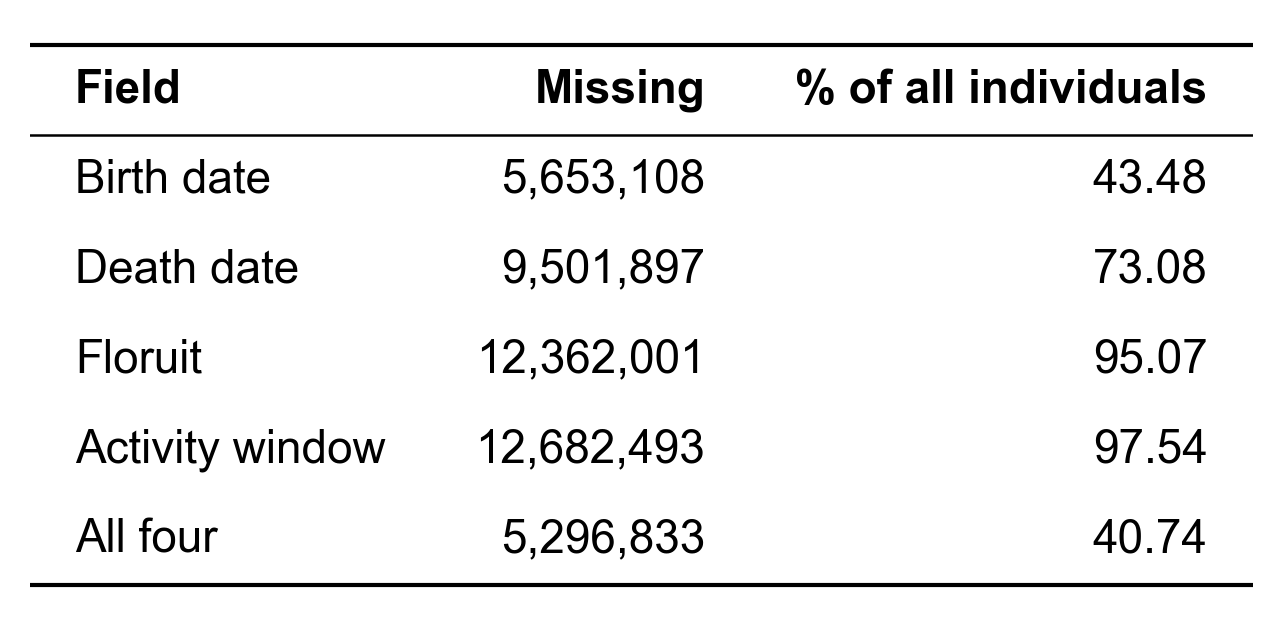

In [7]:
presence = lifetime.with_columns(
    pl.col('qid').is_in(floruit['qid'].implode()).alias('has_floruit'),
    pl.col('qid').is_in(window['qid'].implode()).alias('has_window'),
)
fields = {
    'Birth date': 'has_birth',
    'Death date': 'has_death',
    'Floruit': 'has_floruit',
    'Activity window': 'has_window',
}
missing = pl.DataFrame({
    'Field': list(fields),
    'Missing': [presence.filter(~pl.col(column)).height for column in fields.values()],
})
nothing = presence.filter(~pl.any_horizontal(list(fields.values()))).height
missing = pl.concat([missing, pl.DataFrame({'Field': ['All four'], 'Missing': [nothing]})])
missing = missing.with_columns((100 * pl.col('Missing') / database_size).round(2).alias('% of all individuals'))
show_table(missing)

Birth and death dates at a coarser precision (century, millennium) are not counted above. Individuals with no date at all:

In [8]:
print(f"{presence.filter(~pl.col('has_birth_any')).height:,} individuals have no birth date at all, at any precision")
print(f"{presence.filter(~pl.col('has_death_any')).height:,} individuals have no death date at all, at any precision")

5,515,001 individuals have no birth date at all, at any precision
9,471,463 individuals have no death date at all, at any precision
